# Assignment 1 : Motor parameter identification
#### Student ID: 240057

- both wheels were lifted during recording; data collection was run for both motors: M4/E4 receives $u$ and M3/E3 receives $-u$.
- 2 step sweeps, square wave and sawtooth are present in the data logs

## 1. Motor model

- PWM $p$ is the signed motor command in percent
- applied voltage is approximated by $U=pU_b/100$ in volts
- angle $\theta$ is measured in radians
- speed $\omega$ in rad/s
- time constant $T_m$ , in seconds, is the time to reach 63.2% of final speed after a step from rest
- voltage-to-speed constant $k_e$ has units V*s/rad

Neglecting $L$ inductance gives
$$T_m\dot\omega+\omega=U/k_e,\qquad \dot\theta=\omega.$$
for a constant input, define $\omega_{ss}=U/k_e$ and divide by $T_m$:
$$\dot\omega+\omega/T_m=\omega_{ss}/T_m.$$
multiply by the integrating factor $e^{t/T_m}$:
$$\frac{d}{dt}\left(e^{t/T_m}\omega\right)=\frac{\omega_{ss}}{T_m}e^{t/T_m}.$$
by integrating from zero to $t$, with $\omega(0)=0$, we get
$$e^{t/T_m}\omega(t)=\omega_{ss}(e^{t/T_m}-1),$$
and thus we get:
$$\omega(t)=\omega_{ss}(1-e^{-t/T_m}),\qquad \omega_{ss}=U/k_e.$$
integrating speed with $\theta(0)=0$ gives the fitted angle:
$$\theta(t)=\int_0^t\omega_{ss}(1-e^{-s/T_m})\,ds
=\omega_{ss}[s+T_me^{-s/T_m}]_0^t
=\omega_{ss}(t-T_m+T_me^{-t/T_m}).$$
at one time constant, $\omega(T_m)/\omega_{ss}=1-e^{-1}\approx0.632$, and this explains the 63.2% definition of $T_m$.

| Assumption | How it is assessed here |
|---|---|
| Armature $L$ inductance is negligible | Short transients may reveal mismatch, but inductance is not separately identifiable from these logs. |
| Friction can be represented by the simplified first-order model | Low-PWM speed-line errors and changing Tm show the limits of the approximation; friction coefficients are not separately identified. |
| Load is constant | Both wheels were lifted. There is no floor-load run for comparison. |
| Voltage is constant during each fitted step | A mean voltage is used per step; this approximation does not independently verify loaded voltage stability. |
| A step starts from rest | The coast/rest records supply evidence; the first-sample time offset is retained in the fit. |
| One gain and time constant describe a direction | Parameter-versus-PWM plots and independent signal residuals test this assumption. |

In [78]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d
from IPython.display import display, Image, Markdown

DATA = Path('motor_data') #when running locally)
try:
    from google.colab import files
    uploaded = files.upload()
    DATA.mkdir(exist_ok=True)
    for name, content in uploaded.items():
        (DATA/Path(name).name).write_bytes(content)
except ImportError:
    pass
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
battery = pd.read_csv(DATA/'battery.txt')
MOTORS = {4: 'Left M4/E4', 3: 'Right M3/E3'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def show(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES/f'{name}.png', dpi=140)
    plt.close(fig)
    display(Image(filename=str(FIGURES/f'{name}.png')))

## 2. Read the experiments

files contain **ten numeric columns, without a header**:

`angle_l_deg,time_ms,pwm_l,angle_r_deg,pwm_r,run,phase,segment,onset_ms,battery_voltage_V`

`battery.txt` summarizes before/after voltage values for each series, shared by both motors.

in the step file, `run=1,2` identifies repeated sweeps:
- in signal file, `run=1` is square and `run=2` is sawtooth, recorded consecutively.
- phase 0 is rest, 1 a powered step, 2 coast, 3 square and 4 sawtooth. (program clears each file only once at startup, so the sawtooth does not overwrite the square)

Each step series starts with 3s rest and sweeps -100% to +100% in 10% increments, with 2s powered and 1s coast per level. Each complex signal has amplitude 60%, nominal period 1s and duration 8s, with initial rest and final coast. Square alternates $+60,-60$; sawtooth uses $60[2\operatorname{frac}(t/1\,s)-1]$, rounded to integer PWM.

M3's angle and command are both reverserd to express both wheels in the same robot-forward convention. Raw encoders remain cumulative; differences are taken only in memory. Actual timestamps are used, since the 5ms timer excludes execution and file-writing delays.

**Battery voltage (V)**

mean      min      max
series run                           
signal 1    11.1931  11.1861  11.1991
       2    11.1743  11.1732  11.1991
steps  1    11.1855  11.1602  11.2120
       2    11.1852  11.1602  11.1991

,series,motor,run,before_V,after_V
0,steps,4,1,11.1991,11.1602
1,steps,3,1,11.1991,11.1602
2,steps,4,2,11.1602,11.1861
3,steps,3,2,11.1602,11.1861
4,signal,4,1,11.1861,11.1991
5,signal,3,1,11.1861,11.1991
6,signal,4,2,11.1991,11.1732
7,signal,3,2,11.1991,11.1732


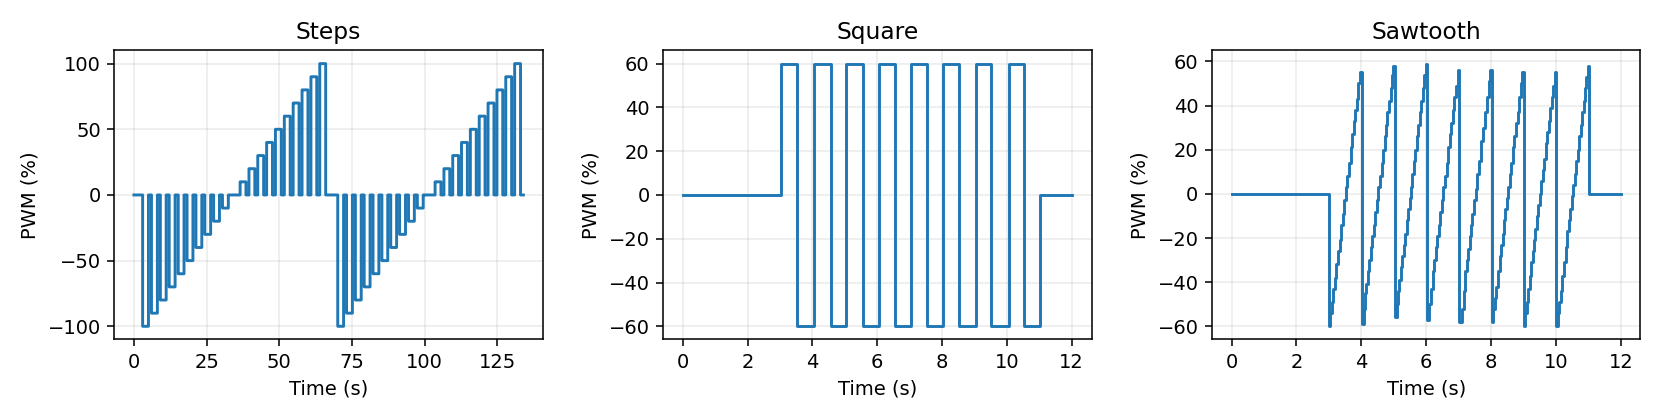

In [79]:
def load(path):
    data = np.loadtxt(path, delimiter=',')
    if data.shape[1] != 10 or not np.isfinite(data).all():
        raise ValueError('Expected ten numeric columns, ending with battery_voltage_V')
    if np.any(np.diff(data[:,1]) <= 0):
        raise ValueError('Sample times must increase')
    motors = []
    for motor, angle_column, pwm_column, sign in [(4,0,2,1), (3,3,4,-1)]:
        motors.append(pd.DataFrame(dict(motor=motor,
            theta=sign*np.deg2rad(data[:,angle_column]), time=data[:,1]/1000,
            pwm=sign*data[:,pwm_column], run=data[:,5].astype(int),
            phase=data[:,6].astype(int), segment=data[:,7].astype(int),
            onset=data[:,8]/1000, battery_voltage_V=data[:,9])))
    return pd.concat(motors, ignore_index=True)

steps = load(DATA/'steps_240057.txt')
signal = load(DATA/'signal_240057.txt')
voltage_summary = pd.concat([steps.assign(series='steps'), signal.assign(series='signal')])
voltage_summary = voltage_summary.groupby(['series','run']).battery_voltage_V.agg(['mean','min','max'])
display(Markdown('**Battery voltage (V)**'))
display(voltage_summary.round(4))
display(battery.round(4))
fig, axes = plt.subplots(1,3, figsize=(12,3))
for ax, (name, g) in zip(axes, [('Steps', steps.query('motor == 4')),
        ('Square', signal.query('motor == 4 and run == 1')),
        ('Sawtooth', signal.query('motor == 4 and run == 2'))]):
    ax.step(g.time-g.time.iloc[0], g.pwm, where='post')
    ax.set(title=name, xlabel='Time (s)', ylabel='PWM (%)')
    ax.grid(alpha=.25)
show(fig, 'recorded_inputs')

*Recorded inputs: both step sweeps and the two signals. The motors receive the same command after the polarity conversion.*

## 3. Fit the step responses

Every powered, nonzero segment is fitted independently. We retain its command onset: the first encoder sample arrives later, so the fitted observation is $\theta(t)-\theta(t_{first})$. Standard errors come from the covariance matrix; they describe uncertainty within this model, not all systematic errors.

`model(t, speed, T_m)` is the angle equation derived above. `fit_run(t, angle)` adjusts speed and Tm until that equation follows one recorded step, then returns the two estimates and their standard errors. The speed guess comes from the last quarter of the step; bounds keep Tm positive and speed in the observed rotation direction. The outer loop repeats this calculation for each motor, run and nonzero PWM level.

Writing the fitted parameters as $\hat\beta=(\hat\omega_{ss},\hat T_m)$ and the covariance returned by `curve_fit` as $C$, the reported one-standard-error estimates are
$$\operatorname{SE}(\hat\omega_{ss})=\sqrt{C_{11}},\qquad
\operatorname{SE}(\hat T_m)=\sqrt{C_{22}}.$$

Unresolved time constants are flagged and excluded from $T_m$ averages and error-bar plots; their speed estimates remain available. The zero-PWM plateau is not a nonzero step response.

`Tm_se` is the standard error of the fitted time constant. If the fit reaches a bound or the samples do not determine its transient curvature, this uncertainty can become enormous. The table then shows **unresolved** for Tm and Tm_se rather than presenting those optimizer numbers as meaningful motor parameters; `resolved=False` identifies the row.

In [80]:
def model(t, speed, T_m):
    return speed*(t - T_m + T_m*np.exp(-t/T_m))

def fit_run(t, angle):
    # Fit differences because the first sample may follow the command onset.
    def observed(t, speed, T_m):
        return model(t,speed,T_m)-model(t[0],speed,T_m)
    tail = max(5,len(t)//4)
    initial_speed = np.polyfit(t[-tail:],angle[-tail:],1)[0]
    bounds = ([0,.001],[200,2]) if initial_speed > 0 else ([-200,.001],[0,2])
    parameters, covariance = curve_fit(observed,t,angle,p0=[initial_speed,.1],
                                       bounds=bounds,maxfev=20000)
    return parameters, np.sqrt(np.diag(covariance))

rows = []
for (motor, run, segment), g in steps.query('phase == 1 and pwm != 0').groupby(['motor','run','segment']):
    t = g.time.to_numpy()-g.onset.iloc[0]
    y = g.theta.to_numpy()-g.theta.iloc[0]
    pwm = g.pwm.iloc[0]
    (speed, T), se = fit_run(t,y)
    resolved = .0011 < T < 1.99 and np.isfinite(se).all() and se[1] <= max(.5,2*T)
    rows.append(dict(motor=motor, run=run, segment=segment, pwm=pwm, speed=speed,
        speed_se=se[0], Tm=T, Tm_se=se[1], resolved=resolved,
        battery_voltage_V=g.battery_voltage_V.mean(), voltage_V=pwm*g.battery_voltage_V.mean()/100,
        step_rmse=np.sqrt(np.mean((y-(model(t,speed,T)-model(t[0],speed,T)))**2))))
fits = pd.DataFrame(rows)
for motor, label in MOTORS.items():
    display(Markdown('**'+label+' — speed in rad/s; Tm in seconds; errors are 1 s.e.**'))
    table = fits.query('motor == @motor').drop(columns=['motor','segment']).round(4)
    for column in ['Tm','Tm_se']:
        table[column] = table[column].astype(object).where(table.resolved,'unresolved')
    display(table)

**Left M4/E4 — speed in rad/s; Tm in seconds; errors are 1 s.e.**

,run,pwm,speed,speed_se,Tm,Tm_se,resolved,battery_voltage_V,voltage_V,step_rmse
40,1,-100.0,-13.5431,0.0074,0.0516,0.0008,True,11.1914,-11.1914,0.0300
41,1,-90.0,-12.2636,0.0107,0.0806,0.0011,True,11.1861,-10.0675,0.0417
42,1,-80.0,-11.2879,0.0069,0.114,0.0007,True,11.1861,-8.9489,0.0254
43,1,-70.0,-10.2491,0.0072,0.1572,0.0008,True,11.2120,-7.8484,0.0244
44,1,-60.0,-9.2701,0.0074,0.1912,0.001,True,11.1887,-6.7132,0.0223
45,1,-50.0,-8.4491,0.0096,0.2163,0.0014,True,11.1861,-5.5931,0.0280
46,1,-40.0,-7.7265,0.0059,0.2358,0.0009,True,11.1861,-4.4745,0.0163
47,1,-30.0,-6.3116,0.0141,0.2967,0.0027,True,11.1861,-3.3558,0.0328
48,1,-20.0,-5.0563,0.0082,0.2846,0.0019,True,11.1732,-2.2346,0.0189
49,1,-10.0,-3.5156,0.0074,0.319,0.0026,True,11.1834,-1.1183,0.0159


**Right M3/E3 — speed in rad/s; Tm in seconds; errors are 1 s.e.**

,run,pwm,speed,speed_se,Tm,Tm_se,resolved,battery_voltage_V,voltage_V,step_rmse
0,1,-100.0,-14.7104,0.0047,0.0637,0.0004,True,11.1914,-11.1914,0.0187
1,1,-90.0,-13.6189,0.0045,0.0954,0.0004,True,11.1861,-10.0675,0.0170
2,1,-80.0,-12.6997,0.0037,0.1119,0.0003,True,11.1861,-8.9489,0.0135
3,1,-70.0,-11.7320,0.0038,0.1793,0.0004,True,11.2120,-7.8484,0.0123
4,1,-60.0,-10.7571,0.0057,0.2223,0.0006,True,11.1887,-6.7132,0.0158
5,1,-50.0,-9.9424,0.0060,0.2476,0.0007,True,11.1861,-5.5931,0.0159
6,1,-40.0,-9.0827,0.0151,0.1297,0.002,True,11.1861,-4.4745,0.0554
7,1,-30.0,-7.7837,0.0066,0.3206,0.001,True,11.1861,-3.3558,0.0144
8,1,-20.0,-6.3827,0.0077,0.341,0.0015,True,11.1732,-2.2346,0.0151
9,1,-10.0,-4.6013,0.0052,0.3945,0.0014,True,11.1834,-1.1183,0.0092


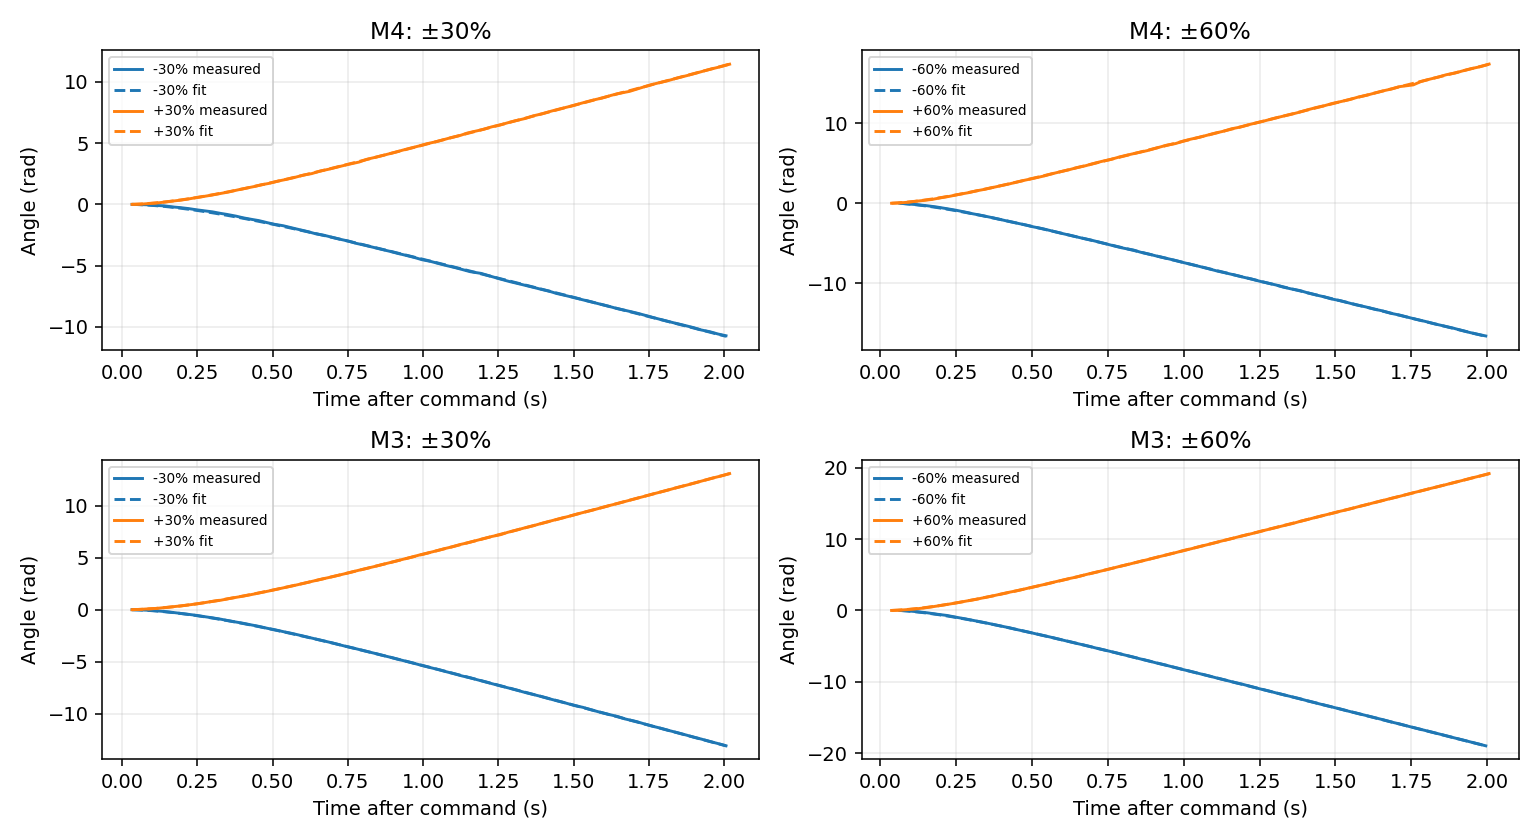

In [81]:
fig, axes = plt.subplots(2,2, figsize=(11,6))
for i, motor in enumerate(MOTORS):
    for ax, level in zip(axes[i], [30,60]):
        for pwm in [-level,level]:
            r = fits.query('motor == @motor and run == 1 and pwm == @pwm').iloc[0]
            g = steps[(steps.motor == motor) & (steps.segment == r.segment)]
            t = g.time.to_numpy()-g.onset.iloc[0]
            line, = ax.plot(t, g.theta-g.theta.iloc[0], label=f'{pwm:+}% measured')
            ax.plot(t, model(t,r.speed,r.Tm)-model(t[0],r.speed,r.Tm),
                    '--', color=line.get_color(), label=f'{pwm:+}% fit')
        ax.set(title=f'M{motor}: ±{level}%', xlabel='Time after command (s)', ylabel='Angle (rad)')
        ax.legend(fontsize=7)
        ax.grid(alpha=.25)
show(fig, 'step_responses')

*Step responses: measured and fitted signed angles at ±30% and ±60% for both motors.*

## 4. Speed, time constant and motor parameters

Fit the speed trend separately for each motor and direction over **30-80% PWM**, retaining its intercept: $\omega_{ss}=ap+b$. With a constant battery voltage, $k_e=U_b/(100a)$. The code fits speed against applied voltage directly, so different series voltages are also supported. Mean $T_m$ uses the same range. These are effective parameters for lifted wheels.

The conversion follows from $p=100U/U_b$:
$$\omega_{ss}=a\frac{100U}{U_b}+b=s_U U+b,\qquad
s_U=\frac{100a}{U_b},\qquad k_e=\frac{1}{s_U}=\frac{U_b}{100a}.$$
Thus **the speed-voltage slope is $1/k_e$**, not $k_e$. With varying battery voltages, the fitted $s_U$ is obtained directly from the individual $(U,\omega_{ss})$ pairs. Retaining the intercept describes the fitted operating range; $U/\omega_{ss}$ at one nonzero-intercept point need not equal this slope-derived constant.

For $n$ accepted fits in the selected motor/direction range, the reported average is
$$\overline T_m=\frac{1}{n}\sum_{j=1}^n T_{m,j}.$$

For the strict constant-parameter validation model, also fit speed versus applied voltage **through zero** in the same range. Its gain $g_U=\sum U\omega/\sum U^2$ gives $k_{e,0}=1/g_U$, shown separately. Dropping a fitted intercept while keeping its original slope would give an inconsistent baseline.

Every ±10% step visibly moves. Thus any stationary region is **below 10% in each direction**; the exact threshold was not resolved. Shading marks this unresolved region rather than an invented dead-zone parameter.

**Left M4/E4**

,direction,dead_zone,slope,intercept,ke,Tm,battery_voltage_V,ke_zero
2,Backward,<10%; unresolved,0.0965,-3.5770,1.1596,0.1967,11.1887,0.7180
3,Forward,<10%; unresolved,0.1014,3.6528,1.1036,0.1937,11.1847,0.6906


**Right M3/E3**

,direction,dead_zone,slope,intercept,ke,Tm,battery_voltage_V,ke_zero
0,Backward,<10%; unresolved,0.0951,-5.1589,1.1775,0.2196,11.1887,0.6196
1,Forward,<10%; unresolved,0.0936,5.2173,1.1958,0.2364,11.1847,0.6211


**Worked calculation: M4 forward**

For the +60% step in repeat 1, $U=(60/100)\times 11.186130=6.711678\ \mathrm{V}$.

The 30–80% speed–voltage fit gives $s_U=0.906138\ \mathrm{rad\,s^{-1}\,V^{-1}}$, so $k_e=1/s_U=1.103585\ \mathrm{V\,s/rad}$.

The mean time constant over the accepted fits in that range is $\overline T_m=0.193684\ \mathrm{s}$. These numbers update from the current inputs when rerun.

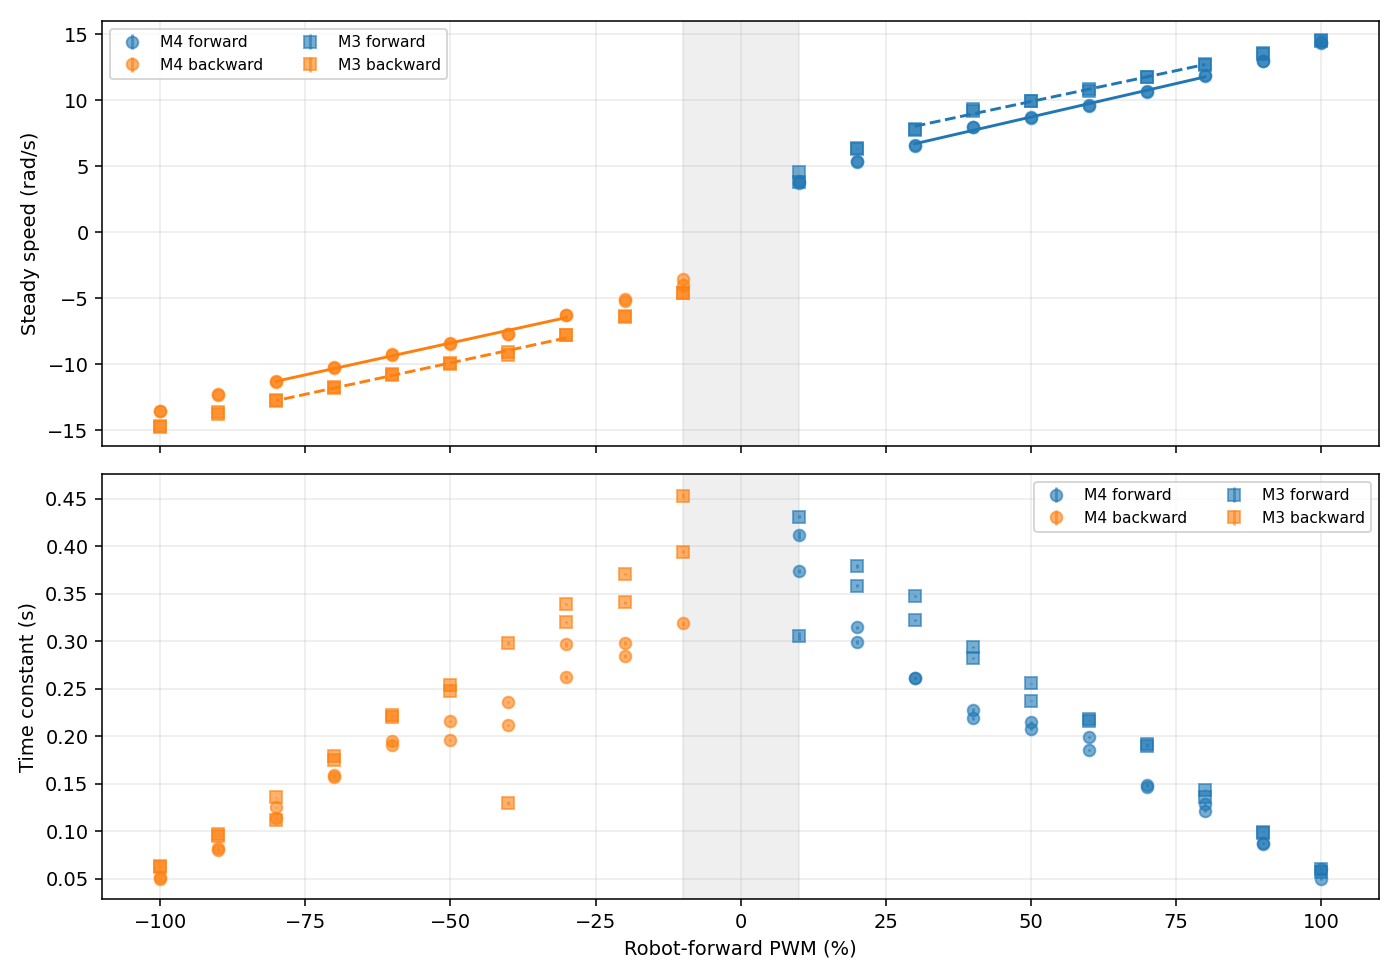

In [82]:
parameters = []
for (motor, direction), g in fits.groupby(['motor', fits.pwm.gt(0)]):
    selected = g[g.resolved & g.pwm.abs().between(30,80)]
    slope, intercept = np.polyfit(selected.pwm, selected.speed, 1)
    voltage_slope = np.polyfit(selected.voltage_V,selected.speed,1)[0]
    gain = np.dot(selected.voltage_V,selected.speed)/np.dot(selected.voltage_V,selected.voltage_V)
    parameters.append(dict(motor=motor, direction='Forward' if direction else 'Backward',
        sign=1 if direction else -1, dead_zone='<10%; unresolved', slope=slope, intercept=intercept,
        ke=1/voltage_slope, Tm=selected.Tm.mean(), battery_voltage_V=selected.battery_voltage_V.mean(),
        voltage_gain_zero=gain, ke_zero=1/gain))

params = pd.DataFrame(parameters)
for motor, label in MOTORS.items():
    display(Markdown('**'+label+'**'))
    display(params.query('motor == @motor').drop(columns=['motor','sign','voltage_gain_zero']).round(4))

example = params.query('motor == 4 and sign == 1').iloc[0]
step_example = fits.query('motor == 4 and run == 1 and pwm == 60').iloc[0]
display(Markdown(fr'''**Worked calculation: M4 forward**

For the +60% step in repeat 1, $U=(60/100)\times {step_example.battery_voltage_V:.6f}={step_example.voltage_V:.6f}\ \mathrm{{V}}$.

The 30-80% speed-voltage fit gives $s_U={1/example.ke:.6f}\ \mathrm{{rad\,s^{{-1}}\,V^{{-1}}}}$, so $k_e=1/s_U={example.ke:.6f}\ \mathrm{{V\,s/rad}}$.

The mean time constant over the accepted fits in that range is $\overline T_m={example.Tm:.6f}\ \mathrm{{s}}$. These numbers update from the current inputs when rerun.'''))

fig, axes = plt.subplots(2,1, figsize=(10,7), sharex=True)
for motor, marker in [(4,'o'),(3,'s')]:
    for sign, color in [(1,'tab:blue'),(-1,'tab:orange')]:
        g = fits[(fits.motor == motor) & (np.sign(fits.pwm) == sign)]
        label = f'M{motor} '+('forward' if sign > 0 else 'backward')
        axes[0].errorbar(g.pwm,g.speed,yerr=g.speed_se,fmt=marker,color=color,alpha=.6,label=label)
        r = params[(params.motor == motor) & (params.sign == sign)].iloc[0]
        x = np.array([30,80])*sign
        axes[0].plot(x,r.slope*x+r.intercept,color=color,ls='-' if motor == 4 else '--')
        g = g[g.resolved]
        axes[1].errorbar(g.pwm,g.Tm,yerr=g.Tm_se,fmt=marker,color=color,alpha=.6,label=label)

for ax, ylabel in zip(axes, ['Steady speed (rad/s)','Time constant (s)']):
    ax.axvspan(-10,10,color='grey',alpha=.12)
    ax.set(ylabel=ylabel)
    ax.grid(alpha=.25)
    ax.legend(fontsize=8,ncol=2)
axes[1].set(xlabel='Robot-forward PWM (%)')
show(fig, 'speed_and_time_constant')

*Both motors and directions share the axes. Error bars are fit standard errors; lines show the selected 30-80% range. Shading is an unresolved low-PWM region, not a measured ±10% dead zone.*

## 5. Simulate the square and sawtooth recordings

This is the assignment's **mathematical simulation**: predict the real motor's response from the recorded PWM and compare it with the encoder measurements. A separate run in TRIK Studio's 2D simulator is not needed for this comparison.

Compare two first-order models, both identified **only from the step tests**:

- **Constant parameters:** the direction-specific through-zero gain and mean $T_m$, equivalent to the assignment's $U/k_e$ model.
- **Step-level parameters:** voltage-normalized steady speeds and resolved $T_m$ are averaged across the step repeats and interpolated between PWM levels. The speed curve is scaled by the signal battery voltage. This is an empirical extension, not a constant-$k_e$ model; no dead-zone threshold is assigned.

**Step-level model formula**

For each motor and tested signed PWM level $p_j$, average the repeat estimates:
$$G_j=\operatorname{mean}_r\!\left(\frac{\hat\omega_{ss,jr}}{\overline V_{b,jr}}\right),\qquad
\tau_j=\operatorname{mean}_{r\in R_j}\hat T_{m,jr},$$
where $\overline V_{b,jr}$ is the step's mean battery voltage and $R_j$ contains resolved time-constant fits. Define $G(p)$ and $\tau(p)$ by linear interpolation. Between neighbouring knots, either curve uses
$$f(p)=f_j+\frac{p-p_j}{p_{j+1}-p_j}(f_{j+1}-f_j),\qquad p_j\le p\le p_{j+1}.$$
The resulting model is
$$\boxed{\dot\omega=\frac{V_b(t)G(p(t))-\omega}{\tau(p(t))},\qquad\dot\theta=\omega.}$$
This replaces the simple model's $G(p)=p/(100k_{e,0,d})$ and $\tau(p)=\overline T_{m,d}$ with PWM-dependent curves; $d$ denotes direction. Both curves use signed PWM. At zero, $G(0)=0$ and $\tau(0)=[\tau(-10)+\tau(10)]/2$, matching the implementation.

PWM is held between its logged command onsets. Exact first-order propagation retains speed and angle through reversals. Using powered-step $T_m$ during coast is approximate for both models. Neither model is adjusted to the signal results.

**`simulate_motor` logic:** start with zero speed and angle; merge sample times with command-change times; calculate the equilibrium speed for each held input; move the current speed toward that equilibrium according to Tm; integrate the resulting speed into angle. It returns simulated speed and angle at the recorded sample times. This is a numerical motor simulation, not a parameter-fitting step.

Speed uses `np.gradient` with actual timestamps. A centered **five-sample mean** is applied to both measured and predicted speed. Raw speed metrics are also reported. Scores exclude initial rest and include final coast. For measured values $y_i$, predictions $\hat y_i$ and $N$ scored samples,
$$e_i=y_i-\hat y_i,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{N}\sum_{i=1}^N e_i^2},\qquad
\mathrm{Fit}=100\left(1-\frac{\lVert y-\hat y\rVert_2}{\lVert y-\overline y\rVert_2}\right).$$
RMSE units are rad for angle and rad/s for speed. A fit of 100% is perfect; negative fit means worse than a constant-mean prediction.

In [83]:
def smooth(y):
    return uniform_filter1d(y, size=5, mode='nearest')

def simulate_motor(g, motor, model_name):
    t = g.time.to_numpy()
    changes = g.pwm.ne(g.pwm.shift()).to_numpy()
    onset, command = g.onset.to_numpy()[changes], g.pwm.to_numpy()[changes]
    grid = np.unique(np.r_[t, onset])
    held = command[np.maximum(0,np.searchsorted(onset,grid,side='right')-1)]
    voltage = g.battery_voltage_V.to_numpy()[np.maximum(0,np.searchsorted(t,grid,side='right')-1)]
    motor_fits = fits.query('motor == @motor').copy()
    motor_fits['speed_per_volt'] = motor_fits.speed/motor_fits.battery_voltage_V
    levels = motor_fits.groupby('pwm').speed_per_volt.mean()
    times = fits.query('motor == @motor and resolved').groupby('pwm').Tm.mean()
    levels.loc[0], times.loc[0] = 0, times.loc[[-10,10]].mean()
    levels, times = levels.sort_index(), times.sort_index()
    w, angle = np.zeros(len(grid)), np.zeros(len(grid))
    for i, dt in enumerate(np.diff(grid)):
        u = held[i]
        sign = np.sign(u) or np.sign(w[i]) or 1
        r = params[(params.motor == motor) & (params.sign == sign)].iloc[0]
        target, T = u*voltage[i]/(100*r.ke_zero), r.Tm
        if model_name == 'Step-level parameters':
            target = voltage[i]*np.interp(u,levels.index,levels.values)
            T = np.interp(u,times.index,times.values)
        decay = np.exp(-dt/T)
        w[i+1] = target+(w[i]-target)*decay
        angle[i+1] = angle[i]+target*dt+(w[i]-target)*T*(1-decay)
    at = np.searchsorted(grid,t)
    return w[at], angle[at]-angle[at][0]

def errors(actual, predicted):
    residual = actual-predicted
    denominator = np.linalg.norm(actual-actual.mean())
    return np.sqrt(np.mean(residual**2)), 100*(1-np.linalg.norm(residual)/denominator)

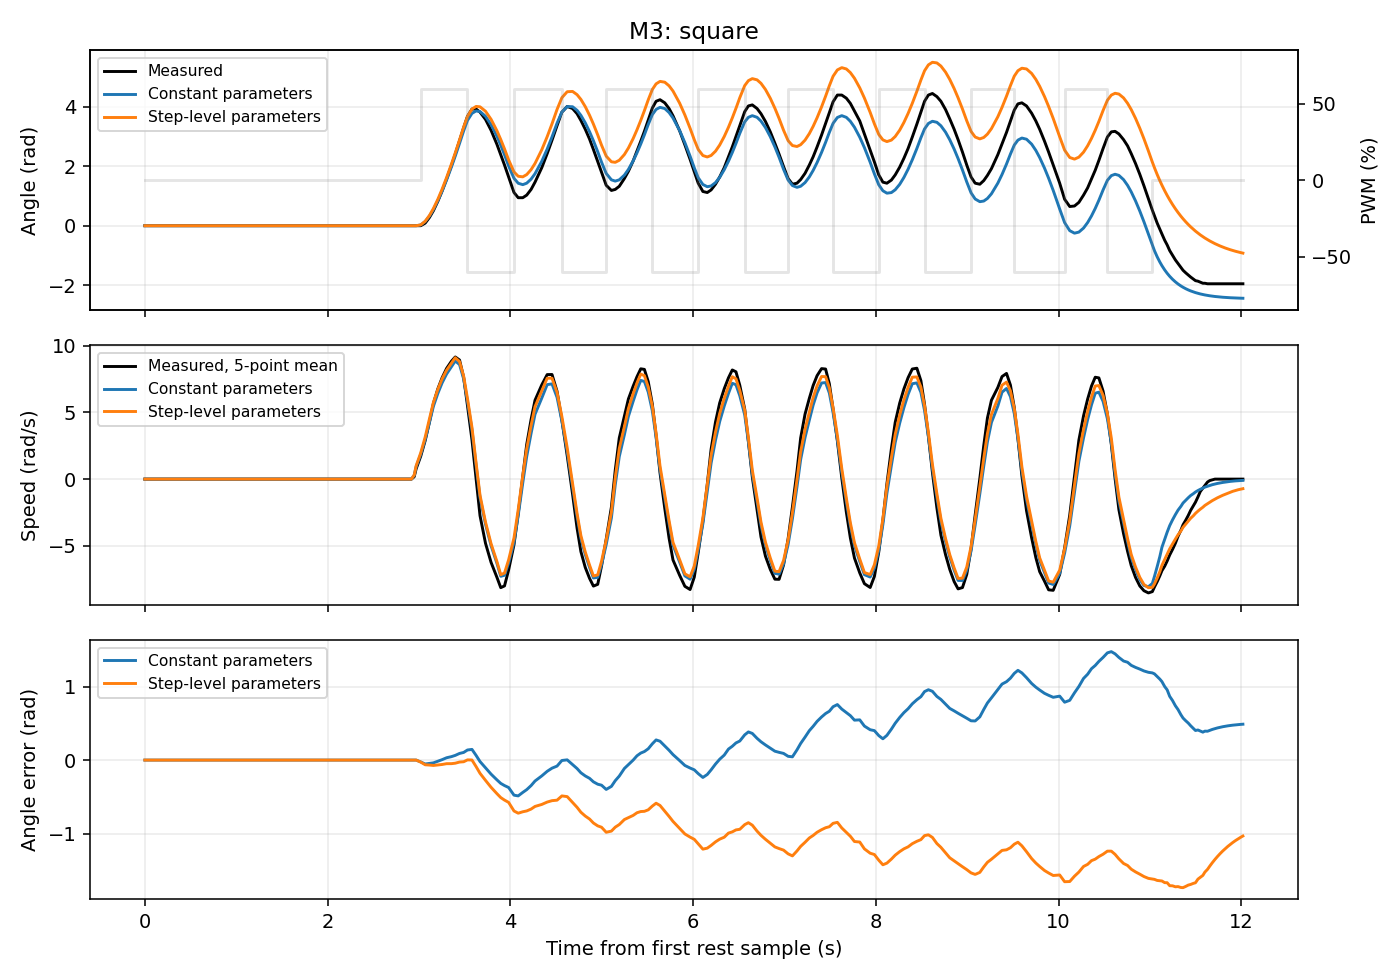

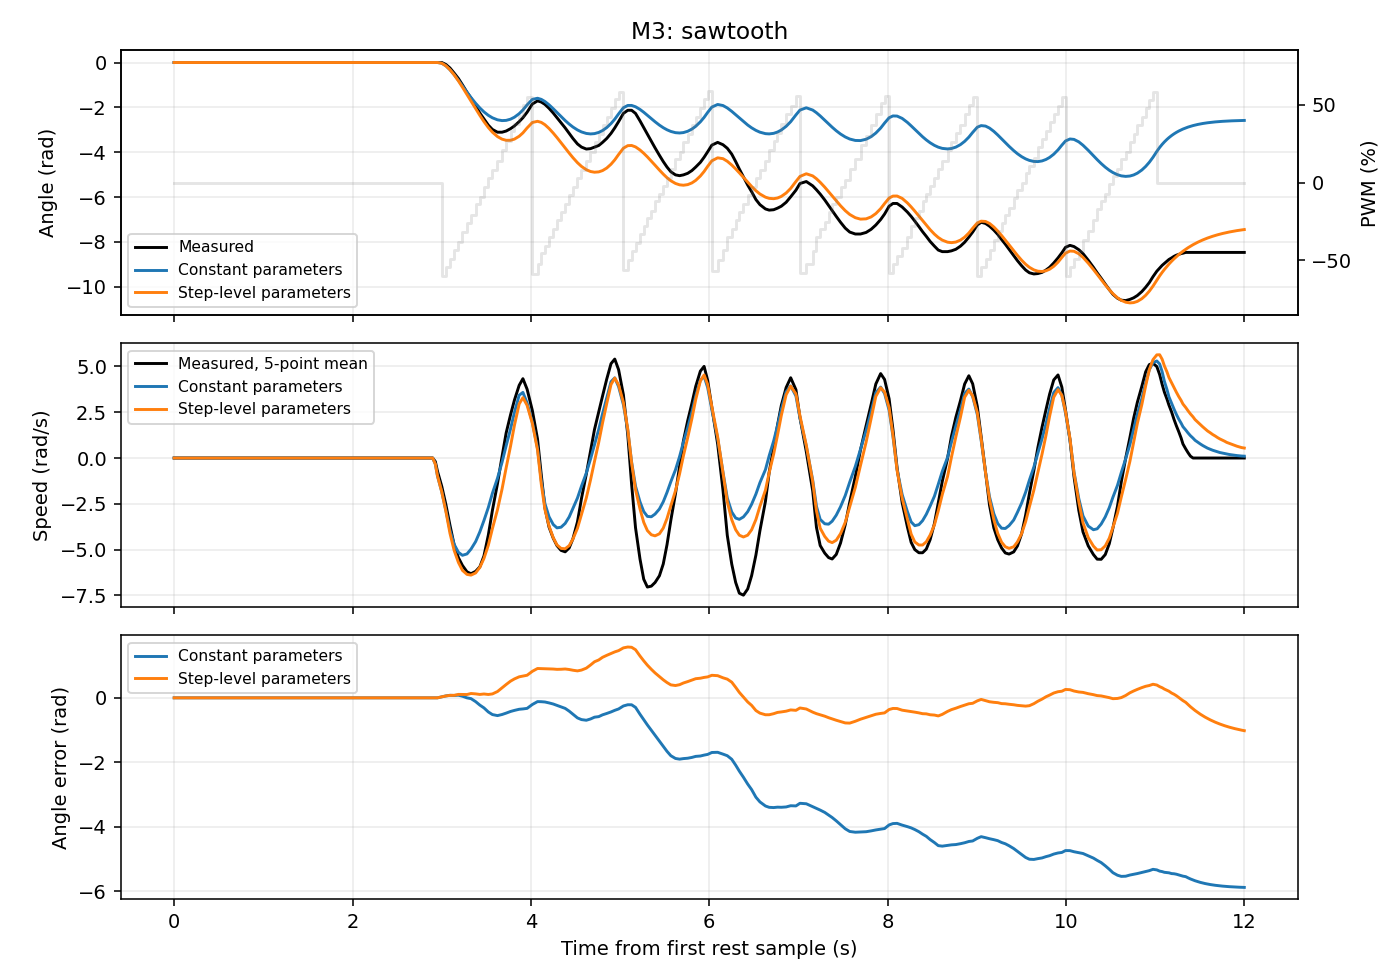

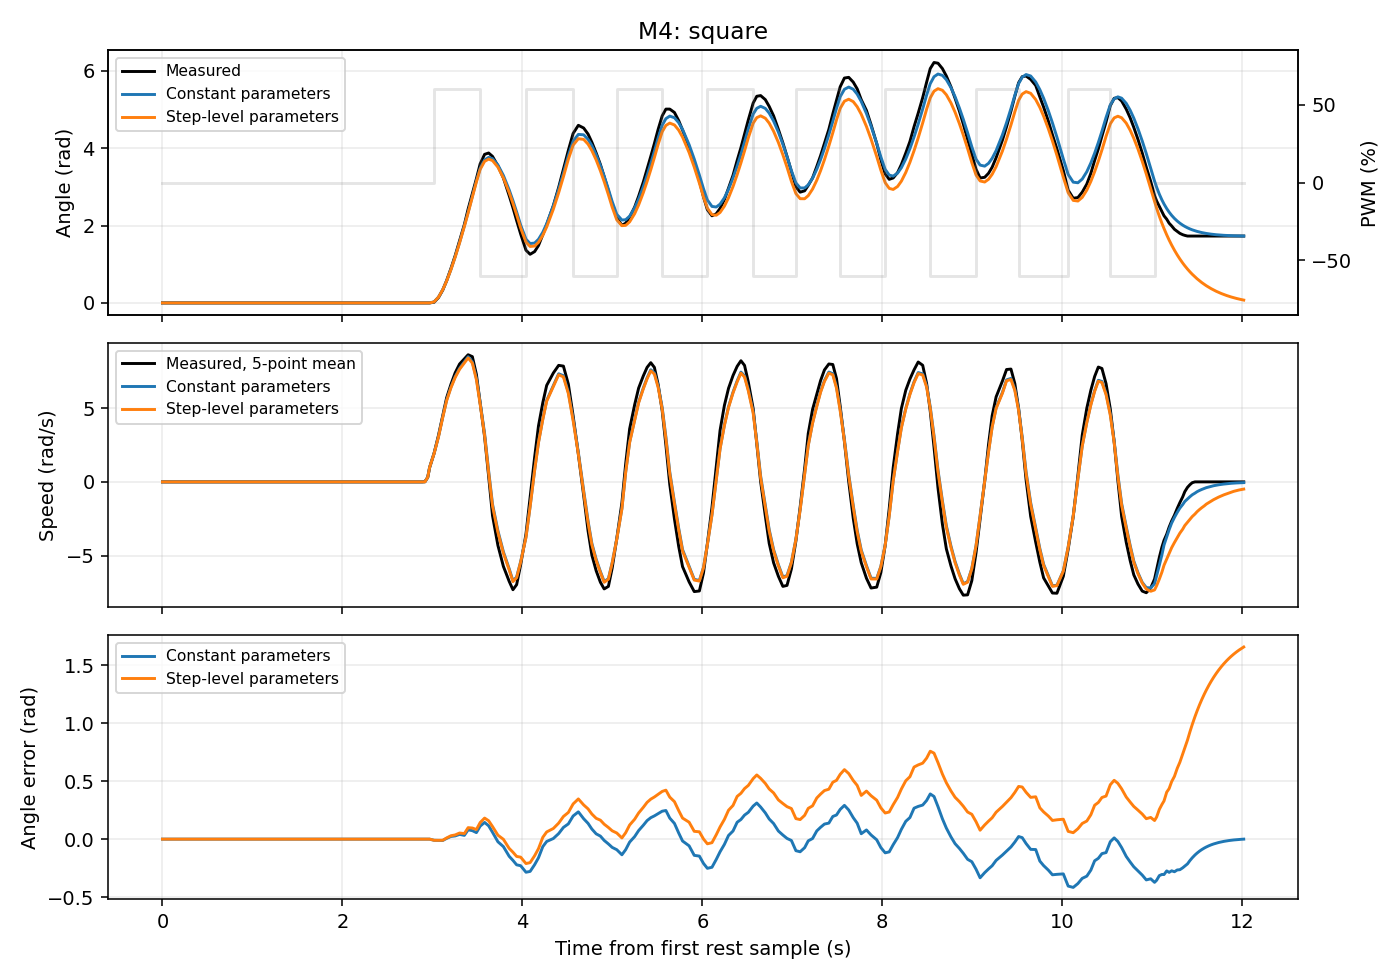

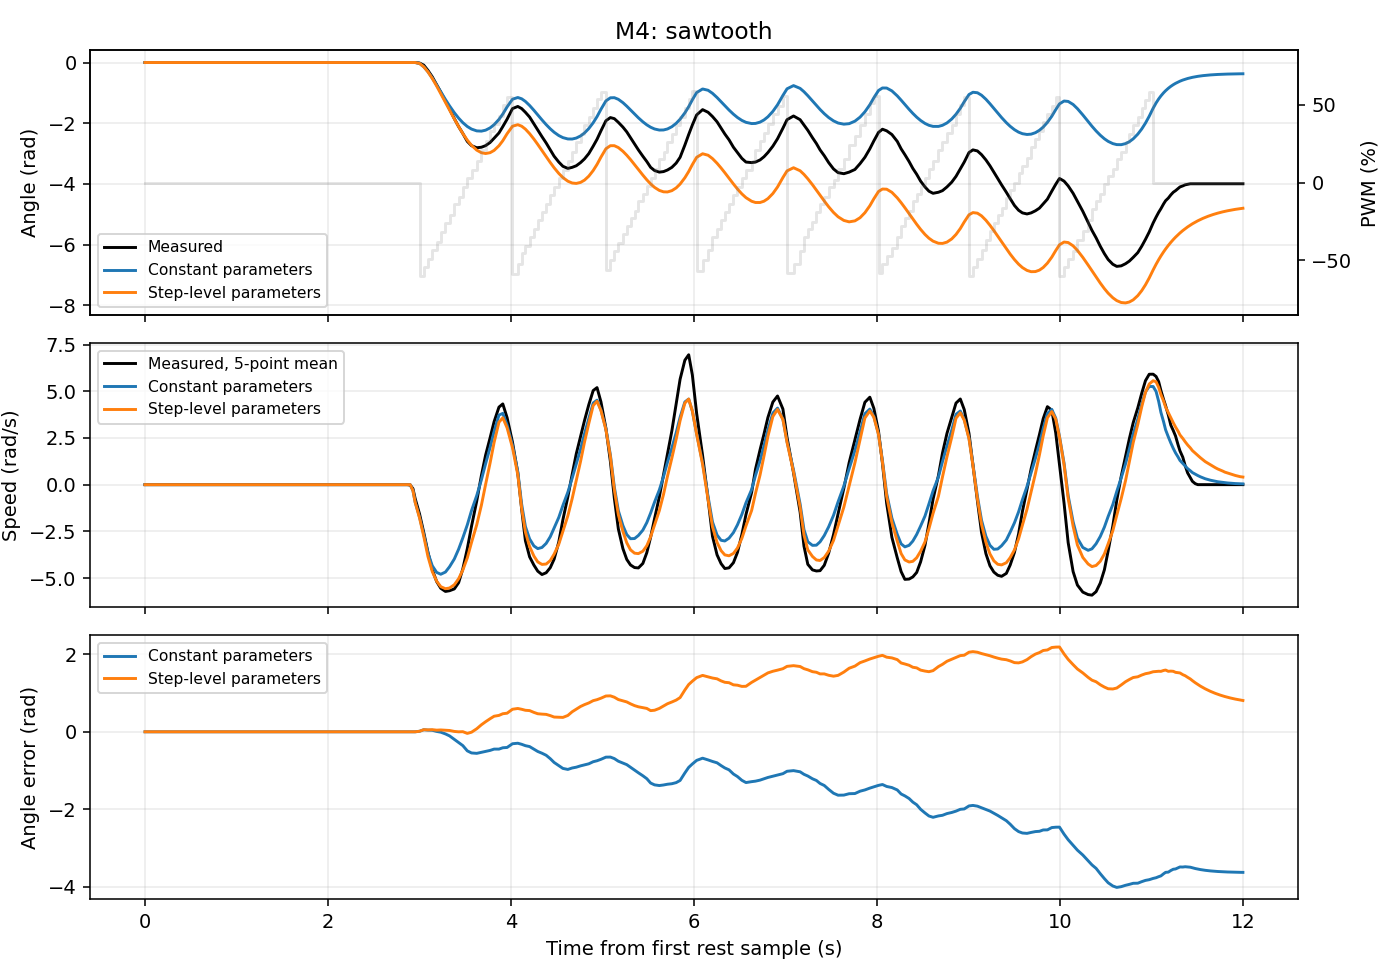

,motor,signal,model,angle_rmse,angle_fit,speed_rmse,speed_fit,raw_speed_rmse,raw_speed_fit,worst_time_s
0,3,square,Constant parameters,0.652,64.987,0.935,83.183,1.057,82.603,10.577
1,3,square,Step-level parameters,1.160,37.736,0.780,85.957,0.901,85.176,11.362
2,3,sawtooth,Constant parameters,3.911,-44.376,1.361,62.257,1.493,62.346,12.001
3,3,sawtooth,Step-level parameters,0.604,77.686,1.176,67.387,1.281,67.685,5.087
4,4,square,Constant parameters,0.182,87.125,0.683,86.840,0.820,85.616,10.122
5,4,square,Step-level parameters,0.569,59.700,0.927,82.124,1.035,81.847,12.017
6,4,sawtooth,Constant parameters,2.257,-74.419,1.089,68.573,1.214,68.131,10.622
7,4,sawtooth,Step-level parameters,1.342,-3.728,0.932,73.099,1.051,72.404,9.996


In [85]:
scores, predictions = [], {}
models = ['Constant parameters', 'Step-level parameters']
for (motor, run), g in signal.groupby(['motor','run']):
    name = {1:'square',2:'sawtooth'}[run]
    t, angle = g.time.to_numpy()-g.time.iloc[0], g.theta.to_numpy()-g.theta.iloc[0]
    raw_speed = np.gradient(angle,t)
    mask = g.phase.to_numpy() != 0
    fig, axes = plt.subplots(3,1, figsize=(10,7), sharex=True)
    axes[0].plot(t,angle,'k',label='Measured')
    axes[1].plot(t,smooth(raw_speed),'k',label='Measured, 5-point mean')
    for model_name in models:
        speed, predicted = simulate_motor(g,motor,model_name)
        predictions[motor,run,model_name] = (speed,predicted)
        
        axes[0].plot(t,predicted,label=model_name)
        
        axes[1].plot(t,smooth(speed),label=model_name)
        
        axes[2].plot(t,angle-predicted,label=model_name)
        
        rmse, fit = errors(angle[mask],predicted[mask])
        sr, sf = errors(smooth(raw_speed)[mask],smooth(speed)[mask])
        rr, rf = errors(raw_speed[mask],speed[mask])
        
        worst = np.flatnonzero(mask)[np.argmax(abs(angle[mask]-predicted[mask]))]
        scores.append(
            dict(
                motor=motor,signal=name,model=model_name,angle_rmse=rmse,angle_fit=fit,
                speed_rmse=sr,speed_fit=sf,raw_speed_rmse=rr,raw_speed_fit=rf,worst_time_s=t[worst]
            ))

    twin = axes[0].twinx()
    twin.step(t,g.pwm,where='post',color='grey',alpha=.2)
    twin.set(ylabel='PWM (%)',ylim=(-85,85))
    
    for ax, label in zip(axes,['Angle (rad)','Speed (rad/s)','Angle error (rad)']):
        ax.set(ylabel=label)
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    
    axes[0].set(title=f'M{motor}: {name}')
    axes[2].set(xlabel='Time from first rest sample (s)')
    show(fig,f'{name}_M{motor}')
scores = pd.DataFrame(scores)
display(scores.round(3))

### RMSE reduction compared with the simple model

$$\Delta\mathrm{RMSE}=\mathrm{RMSE}_{simple}-\mathrm{RMSE}_{step},\qquad
\mathrm{reduction}(\%)=100\frac{\Delta\mathrm{RMSE}}{\mathrm{RMSE}_{simple}}.$$
Positive means lower error with step-level parameters; negative means higher error. The comparisons use the same scored samples and smoothing as the existing metrics.

In [92]:
rmse_changes = {}
for metric, title in [('angle_rmse','Angle RMSE (rad)'),
                      ('speed_rmse','Speed RMSE (rad/s, five-sample mean)')]:
    table = scores.pivot(index=['motor','signal'], columns='model', values=metric)
    table = table.rename(columns={'Constant parameters':'Simple','Step-level parameters':'Step-level'})
    table.columns.name = None
    table['Difference'] = table['Simple']-table['Step-level']
    table['Reduction (%)'] = 100*table['Difference']/table['Simple']
    rmse_changes[metric] = table.copy()
    display(Markdown('**'+title+'**'))
    display(table.round(4))

**Angle RMSE (rad)**

Simple  Step-level  Difference  Reduction (%)
motor signal                                                 
3     sawtooth  3.9112      0.6045      3.3067        84.5447
      square    0.6522      1.1598     -0.5076       -77.8308
4     sawtooth  2.2569      1.3422      0.9147        40.5297
      square    0.1817      0.5688     -0.3871      -213.0230

**Speed RMSE (rad/s, five-sample mean)**

Simple  Step-level  Difference  Reduction (%)
motor signal                                                 
3     sawtooth  1.3606      1.1757      0.1849        13.5919
      square    0.9347      0.7805      0.1542        16.4985
4     sawtooth  1.0893      0.9325      0.1569        14.3996
      square    0.6826      0.9273     -0.2446       -35.8370

*Independent validation: angle, speed and angle error for each motor and signal. The faint right-axis trace is actual PWM. Initial rest is shown but excluded from the scores.*

The chirp **amplitude-ratio versus frequency** plot does not apply to these recordings: square and sawtooth have a fixed nominal period, not a swept frequency. Their non-sinusoidal harmonics do not by themselves provide the chirp measurements required for that plot.

### Additional calculations at matched PWM

The required $\omega_{ss}$, $T_m$, standard errors, directional slopes, $k_e$, RMSE and fit percentages are already calculated above. The following short comparison adds two useful checks from the reference style: wheel-speed mismatch at the same PWM, and how far the 30-80% straight-line fit misses low-PWM speeds. Positive mismatch means the right wheel is faster in magnitude; positive low-PWM error means the line overpredicts the speed magnitude.

On an ideal differential-drive robot, $v=r(\omega_R+\omega_L)/2$ and $\dot\psi=r(\omega_R-\omega_L)/W$, for wheel radius $r$ and spacing $W$. Thus wheel mismatch predicts a turning tendency. We do not turn lifted-wheel measurements into claimed floor-travel or yaw measurements. No floor-load comparison is possible without a floor run.

In [86]:
speed_by_pwm = fits.groupby(['pwm','motor']).speed.mean().unstack('motor')
matched = speed_by_pwm.loc[[-100,-50,50,100]].rename(columns={4:'left_rad_s',3:'right_rad_s'})
matched['right_minus_left_percent'] = 200*(abs(matched.right_rad_s)-abs(matched.left_rad_s))/(
    abs(matched.right_rad_s)+abs(matched.left_rad_s))
display(Markdown('**Wheel speeds at the same PWM (means of both repeats)**'))
display(matched.round(3))
low_pwm = []
for motor in MOTORS:
    for pwm in [-30,-20,-10,10,20,30]:
        r = params[(params.motor == motor) & (params.sign == np.sign(pwm))].iloc[0]
        measured = speed_by_pwm.loc[pwm,motor]
        predicted = r.slope*pwm+r.intercept
        low_pwm.append(dict(motor=motor,pwm=pwm,measured_rad_s=measured,line_rad_s=predicted,
            magnitude_error_percent=100*(abs(predicted)-abs(measured))/abs(measured)))
display(Markdown('**Low-PWM extrapolation of the 30-80% line**'))
display(pd.DataFrame(low_pwm).round(3))

**Wheel speeds at the same PWM (means of both repeats)**

motor,right_rad_s,left_rad_s,right_minus_left_percent
pwm,,,
-100.0,-14.737,-13.551,8.384
-50.0,-9.982,-8.430,16.854
50.0,9.960,8.704,13.458
100.0,14.516,14.372,0.993


**Low-PWM extrapolation of the 30–80% line**

,motor,pwm,measured_rad_s,line_rad_s,magnitude_error_percent
0,4,-30,-6.283,-6.473,3.018
1,4,-20,-5.132,-5.507,7.314
2,4,-10,-3.770,-4.542,20.489
3,4,10,3.803,4.667,22.720
4,4,20,5.362,5.681,5.948
5,4,30,6.564,6.695,1.990
6,3,-30,-7.802,-8.011,2.674
7,3,-20,-6.410,-7.060,10.148
8,3,-10,-4.593,-6.109,33.019
9,3,10,4.178,6.153,47.267


## 6. Artifacts and repeatability

Quantify sampling jitter, initial zero drift, coasting, repeat differences and reversal delay. Coast travel starts at the last powered sample, so it has sampling-boundary uncertainty. Reversal delay includes inertia and encoder resolution; it does not isolate gear backlash. Smoothing changes sharp physical transitions as well as differentiation noise.

For two repeat or parameter values $x_1,x_2$, the symmetric relative difference used in the tables is
$$\delta_x=100\frac{|x_1-x_2|}{(|x_1|+|x_2|)/2}\ \%.$$
The matched-PWM wheel table instead keeps the sign: $200(|\omega_R|-|\omega_L|)/(|\omega_R|+|\omega_L|)$, positive when the right wheel is faster in magnitude. The low-PWM table reports $100(|\omega_{line}|-|\omega_{measured}|)/|\omega_{measured}|$.

In [87]:
quality, coasts, reversals, noise = [], [], [], []
for kind, data in [('steps',steps),('signal',signal)]:
    for (motor,run), g in data.groupby(['motor','run']):
        dt = 1000*np.diff(g.time)
        rest = g[g.phase == 0]
        quality.append(dict(kind=kind,motor=motor,run=run,start_ms=1000*g.time.iloc[0],
            dt_mean=dt.mean(),dt_min=dt.min(),dt_median=np.median(dt),dt_max=dt.max(),
            zero_range_deg=np.rad2deg(np.ptp(rest.theta)),
            net_angle_deg=np.rad2deg(g.theta.iloc[-1]-g.theta.iloc[0])))
        for _, coast in g[g.phase == 2].groupby('segment'):
            before = g[g.time < coast.time.iloc[0]].iloc[-1]
            predicted_coast = np.nan
            if kind == 'steps' and before.pwm != 0:
                r = fits.query('motor == @motor and run == @run and pwm == @before.pwm').iloc[0]
                if r.resolved:
                    w_off = r.speed*(1-np.exp(-(before.time-before.onset)/r.Tm))
                    predicted_coast = np.rad2deg(-w_off*r.Tm*np.expm1(-(coast.time.iloc[-1]-coast.onset.iloc[0])/r.Tm))
            coasts.append(dict(kind=kind,motor=motor,run=run,pwm=before.pwm,
                travel_deg=np.rad2deg(coast.theta.iloc[-1]-before.theta),powered_Tm_prediction_deg=predicted_coast))
        if kind == 'signal':
            speed = np.gradient(g.theta,g.time)
            changes = abs(np.rad2deg(np.diff(g.theta)))
            noise.append(dict(motor=motor,run=run,encoder_increment_deg=changes[changes>0].min(),
                smoothing_span_ms=4*np.median(dt),raw_minus_smooth_rms=np.sqrt(np.mean((speed-smooth(speed))**2))))
            u, t = g.pwm.to_numpy(), g.time.to_numpy()
            for j in np.flatnonzero(u[1:]*u[:-1] < 0)+1:
                end = np.searchsorted(t,t[j]+.4)
                match = np.flatnonzero(speed[j:end]*np.sign(u[j]) > np.deg2rad(5))
                delay = t[j+match[0]]-g.onset.iloc[j] if len(match) else np.nan
                reversals.append(dict(motor=motor,run=run,delay_ms=1000*delay))
quality, coasts, noise, reversals = map(pd.DataFrame,[quality,coasts,noise,reversals])
paired = fits.pivot(index=['motor','pwm'],columns='run',values=['speed','Tm'])
a,b = paired.xs(1,axis=1,level=1),paired.xs(2,axis=1,level=1)
repeat = 200*abs(a-b)/(abs(a)+abs(b))
unresolved = fits.query('not resolved').set_index(['motor','pwm']).index
repeat.loc[repeat.index.isin(unresolved),'Tm'] = np.nan

for title, table in [
        ('Sampling intervals (ms) and zero drift',quality),
        ('Repeat differences (%), median across PWM',repeat.groupby('motor').median()),
        ('Coast magnitude (deg)',coasts.assign(travel_deg=coasts.travel_deg.abs()).groupby(['kind','motor']).travel_deg.agg(['min','median','max'])),
        ('Coast after ±60% measured versus powered-Tm prediction (deg)',coasts.query('kind == "steps" and abs(pwm) == 60').groupby(['motor','pwm'])[['travel_deg','powered_Tm_prediction_deg']].mean()),
        ('Reversal delay (ms)',reversals.groupby(['motor','run']).delay_ms.agg(['median','max'])),
        ('Quantisation and differentiation',noise)]:
    display(Markdown('**'+title+'**'))
    display(table.round(3))

comparison = []
for motor, g in params.groupby('motor'):
    a,b = g.sort_values('sign').iloc[0],g.sort_values('sign').iloc[1]
    comparison.append(dict(motor=motor,**{key+'_difference_pct':200*abs(a[key]-b[key])/(abs(a[key])+abs(b[key]))
        for key in ['slope','ke','Tm']}))
display(Markdown('**Forward/backward differences (%)**'))
display(pd.DataFrame(comparison).round(3))
spread = params.groupby('sign')[['slope','ke','Tm']].agg(lambda x:200*abs(x.iloc[0]-x.iloc[1])/(abs(x.iloc[0])+abs(x.iloc[1])))
display(Markdown('**Motor-to-motor differences (%), by direction sign**'))
display(spread.round(3))

**Sampling intervals (ms) and zero drift**

,kind,motor,run,start_ms,dt_mean,dt_min,dt_median,dt_max,zero_range_deg,net_angle_deg
0,steps,3,1,251.0,29.052,21.0,28.0,76.0,0.0,-62.0
1,steps,3,2,67343.0,28.962,21.0,29.0,62.0,0.0,96.0
2,steps,4,1,251.0,29.052,21.0,28.0,76.0,0.0,394.0
3,steps,4,2,67343.0,28.962,21.0,29.0,62.0,0.0,404.0
4,signal,3,1,134384.0,38.890,21.0,42.0,74.0,0.0,-112.0
5,signal,3,2,146587.0,38.713,21.0,42.0,72.0,0.0,-485.0
6,signal,4,1,134384.0,38.890,21.0,42.0,74.0,0.0,99.0
7,signal,4,2,146587.0,38.713,21.0,42.0,72.0,0.0,-229.0


**Repeat differences (%), median across PWM**

,speed,Tm
motor,,
3,0.700,5.537
4,0.495,4.638


**Coast magnitude (deg)**

min  median    max
kind   motor                     
signal 3      62.0   113.0  164.0
       4      81.0    86.0   91.0
steps  3       0.0   192.0  374.0
       4       0.0   129.0  248.0

... (6 outputs left out)

**Forward/backward differences (%)**

,motor,slope_difference_pct,ke_difference_pct,Tm_difference_pct
0,3,1.570,1.539,7.362
1,4,4.919,4.948,1.560


**Motor-to-motor differences (%), by direction sign**

,slope,ke,Tm
sign,,,
-1,1.537,1.537,10.985
1,8.022,8.021,19.856


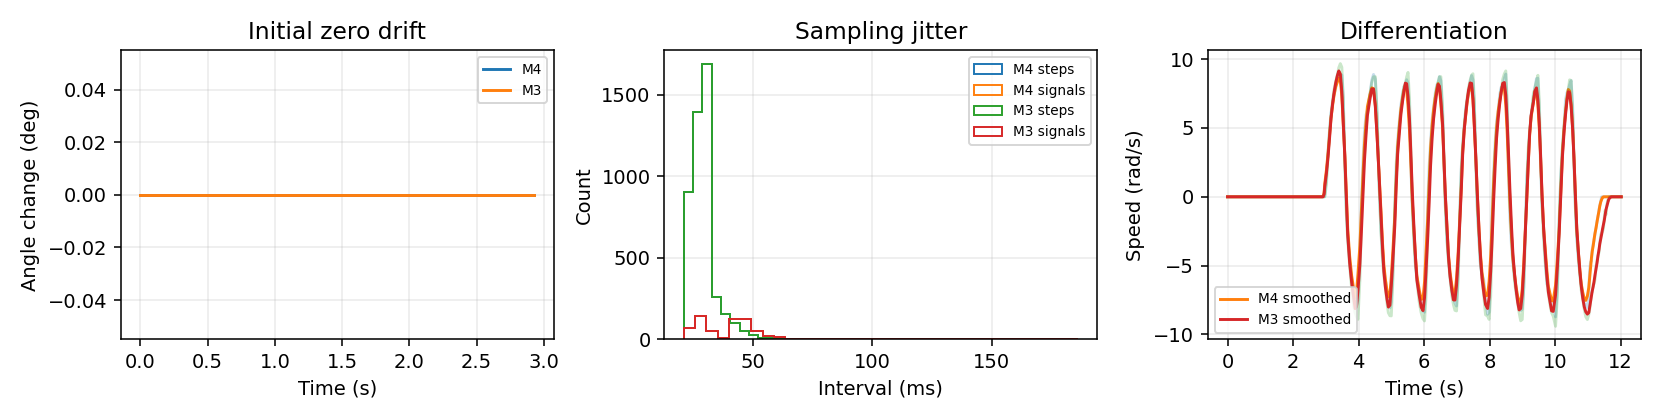

In [88]:
fig, axes = plt.subplots(1,3,figsize=(12,3))
for motor in MOTORS:
    g = steps.query('motor == @motor and run == 1 and phase == 0')
    axes[0].plot(g.time-g.time.iloc[0],np.rad2deg(g.theta-g.theta.iloc[0]),label=f'M{motor}')
    for kind, data in [('steps',steps),('signals',signal)]:
        g = data.query('motor == @motor')
        axes[1].hist(1000*np.diff(g.time),bins=35,histtype='step',label=f'M{motor} {kind}')
    g = signal.query('motor == @motor and run == 1')
    t = g.time.to_numpy()-g.time.iloc[0]
    speed = np.gradient(g.theta,g.time)
    axes[2].plot(t,speed,alpha=.25)
    axes[2].plot(t,smooth(speed),label=f'M{motor} smoothed')
for ax, title, x, y in zip(axes,['Initial zero drift','Sampling jitter','Differentiation'],
        ['Time (s)','Interval (ms)','Time (s)'],['Angle change (deg)','Count','Speed (rad/s)']):
    ax.set(title=title,xlabel=x,ylabel=y)
    ax.legend(fontsize=7)
    ax.grid(alpha=.25)
show(fig,'artifacts')

*Artifact evidence: initial stationary encoders, actual sampling intervals, and differentiated versus smoothed speed. Cumulative angles need not return to zero after physical motion.*

## 7. Discussion

In [90]:
display(Markdown(f'- **Battery voltage:** values span {voltage_summary["min"].min():.4f}-'
    f'{voltage_summary["max"].max():.4f} V. The before/after values are listed in battery.txt.'))

- **Battery voltage:** values span 11.1602–11.2120 V. The before/after values are listed in battery.txt.

In [91]:
agreement = ['**Model agreement**',
    f'- Median step-fit angle RMSE: **{fits.step_rmse.median():.3f} rad** '
    f'({np.rad2deg(fits.step_rmse.median()):.1f}°). Small fitted-step errors do not guarantee accurate validation.']
for (motor, name), g in scores.groupby(['motor','signal']):
    c = g[g.model == 'Constant parameters'].iloc[0]
    e = g[g.model == 'Step-level parameters'].iloc[0]
    agreement.append(f'- **M{motor} {name}:** constant angle fit **{c.angle_fit:.1f}%**, '
        f'RMSE {c.angle_rmse:.3f} rad; largest error at {c.worst_time_s:.2f} s from the first rest sample. '
        f'Step-level angle fit: **{e.angle_fit:.1f}%**, RMSE {e.angle_rmse:.3f} rad.')
display(Markdown('\n\n'.join(agreement)))

**Model agreement**

- Median step-fit angle RMSE: **0.019 rad** (1.1°). Small fitted-step errors do not guarantee accurate validation.

- **M3 sawtooth:** constant angle fit **-44.4%**, RMSE 3.911 rad; largest error at 12.00 s from the first rest sample. Step-level angle fit: **77.7%**, RMSE 0.604 rad.

- **M3 square:** constant angle fit **65.0%**, RMSE 0.652 rad; largest error at 10.58 s from the first rest sample. Step-level angle fit: **37.7%**, RMSE 1.160 rad.

- **M4 sawtooth:** constant angle fit **-74.4%**, RMSE 2.257 rad; largest error at 10.62 s from the first rest sample. Step-level angle fit: **-3.7%**, RMSE 1.342 rad.

- **M4 square:** constant angle fit **87.1%**, RMSE 0.182 rad; largest error at 10.12 s from the first rest sample. Step-level angle fit: **59.7%**, RMSE 0.569 rad.

- The constant model predicts square better than sawtooth. Step-level parameters improve sawtooth but worsen square. Negative fit means worse than the measured mean.
- Tm varies with PWM: **0.050-0.412 s for M4**, **0.057-0.453 s for M3**. M4 at -10%, repeat 2, is unresolved. One constant Tm cannot describe the full range.

**Forward/backward rotation and wheel differences**

- Forward/backward slope differences: **4.9% M4**, **1.6% M3**; mean Tm differences: **1.6%** and **7.4%**.
- Between wheels, slopes differ by **8.0% forward / 1.5% backward**, and Tm by **19.9% / 11.0%**. Use separate calibration for each wheel and direction.
- Both wheels move at ±10%, so the exact dead zone is below the tested resolution. The ke estimates depend on battery voltage; these results apply to lifted wheels.

**Artifacts and consequences for odometry**

- **Zero drift:** 0° change during initial rest. The first timestamp is 251 ms; the clock starts before logging.
- **Sampling:** 28-29 ms median for steps and 42 ms for signals, versus the 5 ms timer. Actual timestamps are needed for speed estimation.
- **Repeatability:** median speed differences are 0.50% for M4 and 0.70% for M3.
- **Coasting:** median step coast angles are 129° and 192°. The powered-Tm model underpredicts coast travel, as the ±60% comparison shows.
- **Reversals:** median square-wave delay is 128 ms for both wheels. This includes inertia, not just backlash.
- **Quantisation:** 1° encoder increments. Five-sample smoothing spans about 168 ms; raw-minus-smoothed RMS is 0.50-0.66 rad/s. Smoothing also blunts real transients.
- **Saturation:** no clear speed plateau through 100% PWM.
- Wheel mismatch, coasting and timing errors accumulate into distance and heading errors.

**Signal choice**

- Square reverses ±60% every 0.5 s, testing repeated acceleration and reversal. Sawtooth sweeps through low PWM before resetting abruptly.
- The 1 s period is several times mean Tm (0.19-0.24 s), making lag visible. Neither signal isolates friction/backlash or gives a full frequency response.

**Limits**

- The PWM grid cannot locate the exact dead zone. Fit errors exclude systematic load, timing and voltage uncertainty; before/after voltages do not measure instantaneous sag.
- Scaling all voltage inputs by 5% scales ke by 5%, while encoder fits and consistently scaled predictions remain unchanged.